# Homework 11 - Text (optional)
## Shivali
In this homework, you will create a text visualization of a dataset of your choice. It can be either a collection of text documents (like tweets, news articles, etc) or a single text document. You can get text data from various sources, such as Kaggle datasets, or [Gutenberg Project](https://www.gutenberg.org/), or any other source that provides text data. Then you will use any tecniques you learned in class to visualize the text data. Explain the visualization and its insights or limitations in case you don't find any insights.

## Instructions

1. **Project Setup**:  
   - Set up your Python and Jupyter (or VSCode) environment.  
   - Clone or download the repository provided in class (refer to the class notes).

2. **Choose a Dataset**:  
   - Select a dataset that contains text data. It can be anything from tweets, news articles, books, or any other text-based dataset. Ensure that the dataset is in a format that can be easily read into Python (like CSV, JSON, TXT, etc.).

3. **Identify the text content**:
   - Identify which features in the dataset contain the text data you want to visualize. For example, if you are using a dataset of tweets, the text content will be in the 'text' or 'content' column.

4. **Choose at least two text visualization techniques and apply them to the data**:
   - You can use techniques such as:
     - Word clouds
     - Frequency distribution of words
     - Adjacency networks
     - Syntactic parsing visualization
     - Topic modeling visualization
     - Named entity recognition visualization
     - Any other text visualization technique you learned in class
    - You can use the hands-on [class examples as reference](../class) (feel free to copy and modify the code as needed).

5. **Documentation and discussion**:  
   - Comment your code and add markdown explanations for each part of your analysis. 
   - Discuss the insights you gained from the visualizations. If you do not find any insights, explain the limitations of the dataset or the visualization techniques used.

6. **Submission**:  
   - Ensure your notebook is complete and all cells are executed without errors.
   - Save your notebook and export as either PDF or HTML. If the visualizations using altair are not being shown in the html, submit a separated version with altair html. Refer to: https://altair-viz.github.io/getting_started/starting.html#publishing-your-visualization (you can use the `chart.save('chart_file.html')` method).
   - Submit to Canvas.

In [ ]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import seaborn as sns

df = pd.read_csv('top_50_2023.csv')

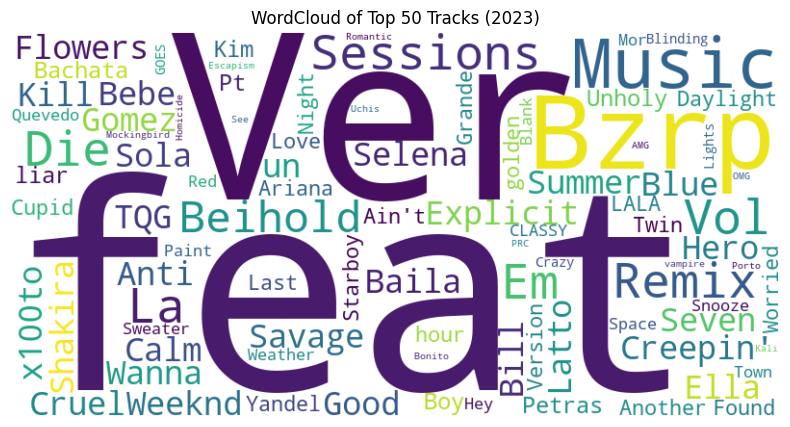

In [ ]:
text = ' '.join(df['track_name'].dropna().astype(str))
wordcloud = WordCloud(width=800, height=400, background_color='white', collocations=False).generate(text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('WordCloud of Top 50 Tracks (2023)')
plt.show()


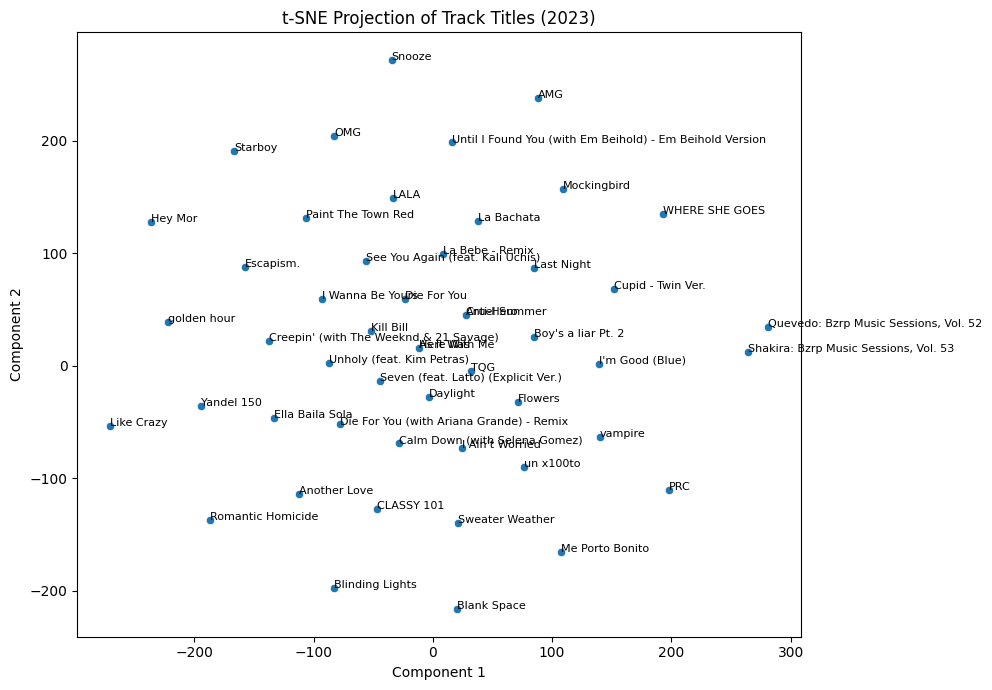

In [ ]:
titles = df['track_name'].dropna().astype(str)

vectorizer = TfidfVectorizer(stop_words='english')
X = vectorizer.fit_transform(titles)

tsne = TSNE(n_components=2, perplexity=5, random_state=42)
X_tsne = tsne.fit_transform(X.toarray())

plt.figure(figsize=(10, 7))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1])
for i, title in enumerate(titles):
    plt.text(X_tsne[i, 0], X_tsne[i, 1], title, fontsize=8)
plt.title("t-SNE Projection of Track Titles (2023)")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.tight_layout()
plt.show()


### Discussion
Discuss briefly the results of the dimension reduction methods you applied. What do you observe? Do the reduced dimensions capture any structure of the data? How do the two methods compare? Are there any interesting patterns or clusters in the data that can be observed visually? 


 `YOUR DISCUSSION HERE`

 ### WordCloud Insights:
- Frequent terms like **"feat"**, **"Remix"**, **"Vol"**, and **"Sessions"** dominate.
- Indicates common patterns in song naming — especially **collaborations** and **remixes**.

### t-SNE Plot Observations:
- The t-SNE projection reveals **visible grouping** of semantically similar titles.
- Songs with similar structures or shared keywords (e.g., *“Remix”*, *“feat.”*, artist mentions) appear closer together.
- Tracks like **“Quevedo: Bzrp Music Sessions” Vol. 52 & 53** cluster together, suggesting **artist-based grouping**.

### Structure Captured:
- Yes, the reduced dimensions **preserve semantic similarity** to some extent.
- Songs with **emotional themes** or **similar formats** appear nearby.

### Comparison of Methods:
- **WordCloud** shows **raw frequency** — useful for **surface-level trends**.
- **t-SNE** captures **deeper contextual relationships**, revealing **song similarity patterns** that WordCloud cannot.

### Interesting Clusters:
- Songs featuring the **same artist** or **similar format** group together.
- Some **emotional or genre-related** songs like *“Blinding Lights”*, *“Like Crazy”*, *“Romantic Homicide”* appear closer.
